# PixelShuffler
Adrián Gutiérrez Roldán, José Luis Rabadán Morejón, Iván Ruiz Guerra

Este notebook constituye el entorno didáctico e interactivo del proyecto, cuyo propósito fundamental es desglosar paso a paso la arquitectura y el flujo interno de PixelShuffler, dado que en el script original (`style_transfer.py`) todos los componentes quedan encapsulados dentro de una única función de consola.

Además, sirve como banco de pruebas ejecutable para experimentar de forma controlada con la ponderación de las funciones de coste, analizar la sensibilidad frente a hiperparámetros clave (tasa de aprendizaje, número de épocas y resolución espacial) e inspeccionar visualmente la convergencia temporal de los píxeles y los mapas de desplazamiento resultantes.

## Configuración del entorno

In [1]:
# Para ejecución en Google Colab
!git clone https://github.com/ivrugue/PixelShuffler
%cd PixelShuffler
%pip install -q monai lpips torchinfo

Cloning into 'PixelShuffler'...
remote: Enumerating objects: 84, done.
remote: Counting objects: 100% (84/84), done.
remote: Compressing objects: 100% (60/60), done.
remote: Total 84 (delta 36), reused 67 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (84/84), 10.93 MiB | 10.78 MiB/s, done.
Resolving deltas: 100% (36/36), done.
/content/PixelShuffler
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 55.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lpips]


In [29]:
import matplotlib.pyplot as plt
import numpy as np

from tqdm.notebook import tqdm

import torch, torch.nn, torch.optim
from torchinfo import summary

from monai.networks.nets import UNet
from monai.networks.blocks import Warp

import lpips
from monai.losses import GlobalMutualInformationLoss
from networks.deform_losses import GradEnergyLoss, BendingEnergyLoss

from utils import compute_style_loss, gram_style_loss, dvf_to_ddf, load_image, set_seed, tensor_to_numpy

Preparamos el entorno para fijar la semilla, asegurando así la reproducibilidad numérica, y detectamos e inicializamos explícitamente la GPU (CUDA) si se encuentra disponible.

In [3]:
# Set random seed
set_seed()

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type == "cuda":
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"Dispositivo activo: GPU ({gpu_name})")
    print(f"VRAM: {vram_gb:.2f} GB")
else:
    print("AVISO: GPU no detectada. La ejecución se realizará en CPU.")

Dispositivo activo: GPU (Tesla T4)
VRAM: 14.56 GB


## Carga y preprocesamiento de imágenes
En primer lugar cargamos y adaptamos las dos imágenes de entrada del sistema: la imagen de contenido ($C$) y la imagen de estilo ($S$). Para posibilitar las operaciones a realizar y calcular correctamente las funciones de pérdida, ambas imágenes deben cumplir una serie de restricciones que resuelve la función `load_image` de `utils.py`:

1. **Ajuste de resolución (`Resize` y `CenterCrop`):** Ambas imágenes se escalan y recortan simétricamente al centro a un tamaño cuadrado fijo para asegurar que comparten las mismas dimensiones.
2. **Normalización tensorial (`ToTensor`):** Transforma los valores discretos $[0, 255]$ a flotantes continuos en el intervalo $[0.0, 1.0]$ y reordena los ejes a la convención convolucional de PyTorch: `[Canales, Alto, Ancho]`.
3. **Dimensión de lote (`unsqueeze(0)`):** Incorpora la dimensión de *batch* ($B=1$), produciendo un tensor final de forma $[1, 3, 512, 512]$ que se transfiere directamente a la GPU.

In [15]:
content_img_path = "Figures/Multiple_Styles.png"
style_img_path = "Figures/Multiple_Styles.png"
size = 512

content_image = load_image(content_img_path, size).to(device)
style_image = load_image(style_img_path, size).to(device)

Visualizamos las imágenes con `matplotlib`, transformándolas previamente con `tensor_to_numpy` (de `utils.py`), que retira el grafo de cálculo (`detach()`), devuelve el tensor a la CPU y recupera el orden de los ejes a `[Alto, Ancho, Canales]`.

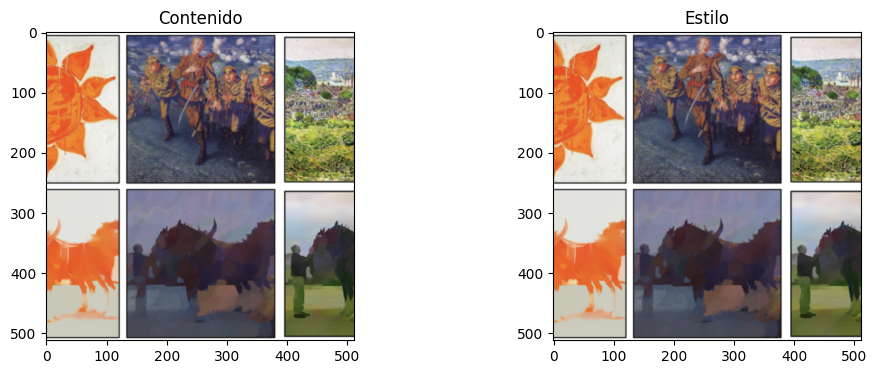

In [9]:
content_np = tensor_to_numpy(content_image)
style_np = tensor_to_numpy(style_image)

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.imshow(content_np)
plt.title("Contenido")

plt.subplot(1,2,2)
plt.imshow(style_np)
plt.title("Estilo")

plt.show()

## Desglose de la arquitectura

### Red U-Net ($\mathcal{N}_\theta$)
* **Entrada (`in_channels=6`):** Recibe apiladas por canales la imagen de estilo $S$ (3 canales RGB) y la imagen de contenido $C$ (3 canales RGB), formando un tensor de dimensión $[1, 6, H, W]$.
* **Procesamiento:** Su rama de contracción reduce progresivamente la resolución para captar la estructura global y las siluetas de la escena, mientras que su rama de expansión vuelve a ampliar el mapa hasta las dimensiones originales apoyándose en conexiones de salto, que rescatan los bordes finos de las primeras capas para ajustar el desplazamiento píxel a píxel.
* **Salida (`out_channels=2`):** Devuelve un campo vectorial bidimensional $D \in \mathbb{R}^{1 \times 2 \times H \times W}$, donde cada píxel contiene los desplazamientos $(\Delta x, \Delta y)$ que indican hacia dónde debe viajar el píxel correspondiente de la imagen de estilo.

In [18]:
reg = UNet(
  spatial_dims=2,               # imagenes en 2D
  in_channels=6,                # 3 canales RGB estilo + 3 canales RGB contenido
  out_channels=2,               # 2 canales de desplazamiento en X e Y
  channels=(32, 64, 128, 128),  # cuántos filtros se aprenden en cada nivel de la U (3 de contracción/expansión y 1 cuello de botella)
  strides=(2, 2, 2),            # factor de reducción espacial: se reduce siempre a la mitad y luego se amplía al doble
  num_res_units=3,              # bloques residuales para estabilizar aprendizaje de capas convolucionales intermedias
).to(device)

Podemos obtener un resumen de la red con `torchinfo.summary` para verificar dos propiedades clave de este método:
* **Arquitectura multiescala:** Se observa cómo la red reduce progresivamente la resolución espacial (512×512 $\rightarrow$ 256×256 con 32 filtros $\rightarrow$ 128×128 con 64 filtros $\rightarrow$ 64×64 con 128 filtros), mientras las conexiones de salto (SkipConnection) unen la información de los bordes de las primeras capas con la de las capas profundas antes de recuperar los 512×512 originales con 2 canales de salida.
* **Ligereza computacional:** Con 1.250.297 parámetros y una huella de memoria de unos 355MB, la red es órdenes de magnitud más ligera que un modelo de difusión o GAN, lo que permite optimizarla desde cero en poco tiempo para cada pareja de imágenes.

In [24]:
summary(reg, input_size=(1, 6, size, size), depth=5)

Layer (type:depth-idx)                                                           Output Shape              Param #
UNet                                                                             [1, 2, 512, 512]          --
├─Sequential: 1-1                                                                [1, 2, 512, 512]          --
│    └─ResidualUnit: 2-1                                                         [1, 32, 256, 256]         --
│    │    └─Conv2d: 3-1                                                          [1, 32, 256, 256]         1,760
│    │    └─Sequential: 3-2                                                      [1, 32, 256, 256]         --
│    │    │    └─Convolution: 4-1                                                [1, 32, 256, 256]         --
│    │    │    │    └─Conv2d: 5-1                                                [1, 32, 256, 256]         1,760
│    │    │    │    └─ADN: 5-2                                                   [1, 32, 256, 256]         1


### Módulo de deformación física
Una vez que la U-Net devuelve el campo de deformación continuo, la capa `Warp` se encarga de trasladar físicamente los píxeles de la imagen de estilo $S$ hacia sus nuevas coordenadas mediante la operación:

$$S_{\text{deformed}}(x, y) = S\big(x + \Delta x, \, y + \Delta y\big)$$

Construimos la clase con los siguientes argumentos:

* **Interpolación bilineal (`"bilinear"`):** Como los desplazamientos $(\Delta x, \Delta y)$ toman valores reales continuos, el color de cada nueva posición se calcula como una media ponderada de los 4 píxeles vecinos más cercanos. Al ser una operación diferenciable, permite que los gradientes fluyan hacia atrás para actualizar los pesos $\theta$ de la U-Net, conservando además la paleta de colores original de $S$.
* **Gestión de bordes (`"border"`):** Si un desplazamiento apunta fuera de los límites de la imagen, replica el píxel del borde más próximo para evitar márgenes negros.

In [25]:
warp_layer = Warp("bilinear", "border").to(device)

/usr/local/lib/python3.13/dist-packages/monai/networks/blocks/warp.py:92: UserWarning: monai.networks.blocks.Warp: Using PyTorch native grid_sample.
  warnings.warn("monai.networks.blocks.Warp: Using PyTorch native grid_sample.")


### Algoritmo de optimización
Dado que la U-Net se inicializa sin preentrenamiento previo, necesitamos un algoritmo que ajuste sus 1,25 millones de parámetros $\theta$ iteración tras iteración para minimizar el error global. En PixelShuffler se emplea el optimizador Adam (Adaptive Moment Estimation):

$$\theta \leftarrow \theta - \eta \nabla_\theta \mathcal{L}_{\text{total}}$$

* **`reg.parameters()`:** Indica al optimizador qué tensores tiene permiso para modificar. Al pasarle únicamente los pesos de la U-Net, garantizamos que solo se actualice la red que predice los desplazamientos.
* **Tasa de aprendizaje ($\eta$):** Controla la magnitud del paso en cada actualización. Adam adapta automáticamente esta tasa para cada parámetro individual en función de la media y la varianza de los gradientes pasados, permitiendo que los píxeles viajen rápido al principio y se estabilicen con precisión al final.

Según el artículo, se probaron distintos valores y encontró que $\eta = 0.003$ ofrecía el equilibrio justo entre avanzar rápido al principio y no desestabilizar la deformación, pero nosotros definiremos la siguiente función para poder experimentar con distintos valores:

In [27]:
def optimizer(reg, lr=3e-3):
  return torch.optim.Adam(reg.parameters(), lr)

### Funciones de coste
Para guiar el desplazamiento espacial de los píxeles sin destruir la coherencia visual, combinamos las funciones de pérdida del método original con varias funciones auxiliares implementadas en los módulos del repositorio (`utils.py` y `networks/deform_losses.py`) que originalmente quedaron sin conectar al flujo principal:

* **Información Mutua Global ($\mathcal{L}_{\text{MI}}$):** Es la función objetivo principal del artículo ($\mathcal{L}_{\text{MI}} = -I(C; S_{\text{deformed}})$). Mide la dependencia estadística entre las regiones de la imagen de contenido $C$ y las del estilo deformado. Al minimizar su valor negativo, fuerza a que los píxeles del cuadro se agrupen siguiendo las siluetas y fronteras de $C$ sin exigir una coincidencia numérica directa de valores RGB.
* **Distancia Perceptual Estructural ($\mathcal{L}_{\text{LPIPS}}$):** Utiliza una red AlexNet preentrenada y congelada para comparar representaciones internas entre la imagen deformada $S_{\text{deformed}}$ y la imagen de contenido $C$. Su objetivo es preservar la integridad geométrica y evitar que los contornos o detalles estructurales del contenido se distorsionen durante la deformación.
* **Pérdida de Estilo ($\mathcal{L}_{\text{Estilo}}$):** Evalúa la similitud textural y cromática entre la imagen deformada $S_{\text{deformed}}$ y la imagen de estilo original $S$ utilizando los mapas de características intermedios extraídos por una red VGG-19 preentrenada y congelada. En nuestro flujo permitimos seleccionar entre dos funciones distintas para ello:
  * **`compute_style_loss`:** Variante empleada por defecto en el script original. Calcula la suma de las distancias euclídeas entre las medias ($\mu$) y las desviaciones típicas ($\sigma$) de cada canal de activación convolucional, favoreciendo la distribución tonal global.
  * **`gram_style_loss` [Extensión]:** Incorporamos una función definida en `utils.py` pero sin enlazar en el código original. Construye las matrices de Gram ($G = F \cdot F^T$) para medir la correlación espacial entre distintos filtros de la red convolucional ($F$) y minimiza el error cuadrático medio entre ellas, favoreciendo la conservación de texturas y trazos locales.
* **Regularización espacial del campo ($\mathcal{L}_{\text{Reg}}$) [Extensión]:** Incorporamos las funciones de energía no usadas en el código original, disponibles en el módulo `networks/deform_losses.py`, para regularizar directamente el campo de deformación $D(x, y)$:
  * **`GradEnergyLoss` (1º orden):** Penaliza las variaciones bruscas de desplazamiento entre píxeles adyacentes, evitando estiramientos o compresiones excesivas en zonas localizadas.
  * **`BendingEnergyLoss` (2º orden):** Penaliza las curvaturas pronunciadas en el campo vectorial, evitando pliegues o discontinuidades irregulares en la deformación.

In [30]:
loss_fn_MI = GlobalMutualInformationLoss()

loss_fn_LPIPS = lpips.LPIPS(net="alex").to(device)

loss_fn_adain = compute_style_loss
loss_fn_gram = gram_style_loss

loss_fn_grad = GradEnergyLoss()
loss_fn_bending = BendingEnergyLoss()

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 126MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


A diferencia de la implementación original, donde los factores de escala estaban fijados internamente y no existía regularización sobre el campo de vectores, asignamos pesos configurables ($\alpha, \beta, \gamma, \lambda$) a cada una de estas funciones en la función de coste total:

$$\mathcal{L}_{\text{total}} = \alpha\,\mathcal{L}_{\text{MI}} + \beta\,(w_i \cdot \mathcal{L}_{\text{LPIPS}}) + \gamma\,(w_i \cdot \mathcal{L}_{\text{Estilo}}) + \lambda\,\mathcal{L}_{\text{Reg}}$$

El factor temporal $w_i$ genera una rampa lineal ascendente desde 0 hasta 0.1 a lo largo de las iteraciones. Esto permite que en las primeras épocas domine la Información Mutua para desplazar libremente los píxeles hacia la estructura del contenido, mientras que las restricciones perceptuales ($\mathcal{L}_{\text{LPIPS}}$ y $\mathcal{L}_{\text{Estilo}}$) se introducen de forma progresiva.

Definimos la siguiente función, adaptada a partir del cálculo del coste total dentro del bucle original, para permitir la personalización en la selección de pesos y de funciones de pérdida:

In [32]:
def calcular_total_loss(
    fixed_image, style_image, moved_image, ddf,
    w, alpha_MI=1., beta_LPIPS=10., gamma_style=0.01, lambda_reg=0.,
    style_mode="adain", reg_mode="bending"):

  total_loss = 0

  if alpha_MI > 0:
      imgloss_MI = loss_fn_MI(moved_image, fixed_image)
      total_loss += alpha_MI * imgloss_MI

  if beta_LPIPS > 0:
      imgloss_LPIPS = loss_fn_LPIPS(moved_image, fixed_image).mean()
      total_loss += beta_LPIPS * w * imgloss_LPIPS

  if gamma_style > 0:
      loss_fn_style = loss_fn_gram if style_mode == "gram" else loss_fn_adain
      style_loss = loss_fn_style(moved_image, style_image)
      total_loss += gamma_style * w * style_loss

  if lambda_reg > 0:
      loss_fn_reg = loss_fn_grad if reg_mode == "grad" else loss_fn_bending
      reg_loss = loss_fn_reg(ddf)
      total_loss += lambda_reg * reg_loss

  return total_loss